/tmp/ipykernel_61967/616632793.py:48: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ignored_patch = mpatches.Patch(color='#ffffff', edgecolor='#cccccc', label='Ignorowane przez przemienność (Copia lustrzana)')


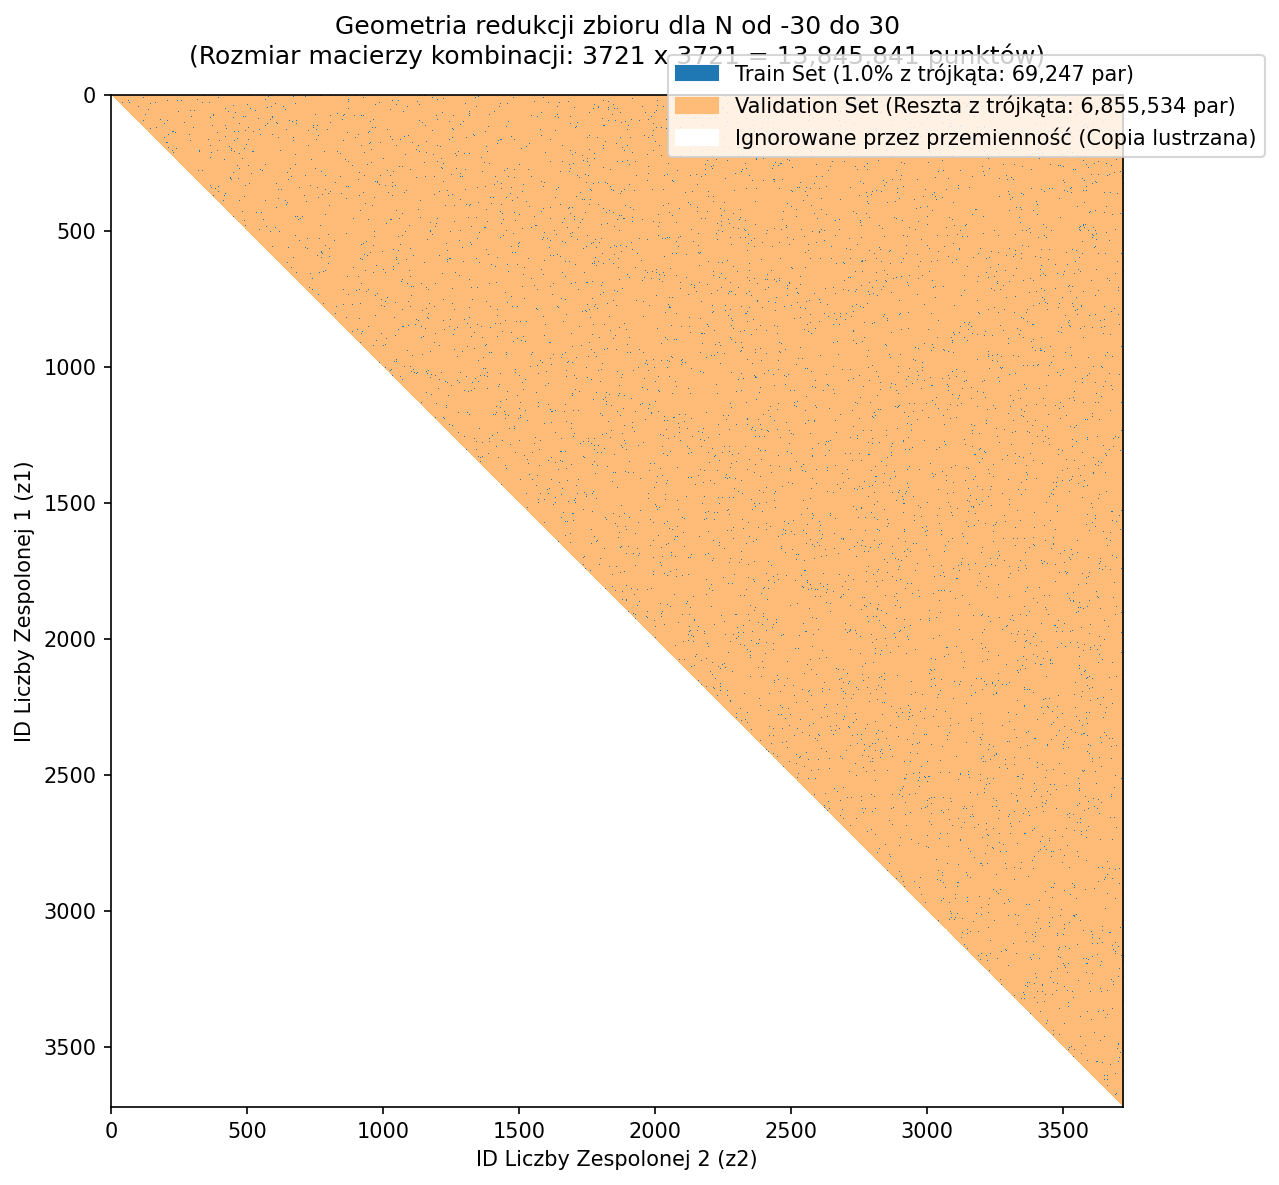

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def visualize_dataset_reduction(min_val=-30, max_val=30, train_frac=0.01, seed=42):
    np.random.seed(seed)
    
    # 1. Generujemy przestrzeń unikalnych liczb zespolonych
    complex_domain = []
    for r in range(min_val, max_val + 1):
        for i in range(min_val, max_val + 1):
            complex_domain.append((r, i))
    K = len(complex_domain)
    
    # 2. Wszystkie możliwe pary (cały gigantyczny zbiór przed redukcją: K x K)
    # Dla wizualizacji stworzymy macierz gęstą K x K, gdzie:
    # 0 = brak punktu, 1 = punkt walidacyjny, 2 = punkt treningowy
    grid = np.zeros((K, K), dtype=int)
    
    # 3. Redukcja przemienności - bierzemy tylko indeksy macierzy trójkątnej (triu)
    triu_indices = np.triu_indices(K)
    unique_pairs_idx = np.column_stack((triu_indices[0], triu_indices[1]))
    total_unique = len(unique_pairs_idx)
    
    # Ustawiamy całą macierz trójkątną jako punkty walidacyjne (kod: 1)
    grid[triu_indices[0], triu_indices[1]] = 1
    
    # 4. Próbkowanie losowe zadany % z unikalnych par na zbiór treningowy
    num_train = int(total_unique * train_frac)
    shuffled_indices = np.random.permutation(total_unique)
    train_selection = unique_pairs_idx[shuffled_indices[:num_train]]
    
    # Oznaczamy wybrane punkty jako treningowe (kod: 2)
    grid[train_selection[:, 0], train_selection[:, 1]] = 2
    
    # --- RYSOWANIE WYKRESU ---
    plt.figure(figsize=(10, 8), dpi=150)
    
    # Definiujemy mapę kolorów: 0 -> biały, 1 -> jasnopomarańczowy (val), 2 -> ciemnoniebieski (train)
    from matplotlib.colors import ListedColormap
    cmap = ListedColormap(['#ffffff', '#ffbb78', '#1f77b4'])
    
    plt.imshow(grid, cmap=cmap, interpolation='nearest')
    
    # Dodajemy legendę rzemieślniczo
    import matplotlib.patches as mpatches
    val_patch = mpatches.Patch(color='#ffbb78', label=f'Validation Set (Reszta z trójkąta: {total_unique - num_train:,} par)')
    train_patch = mpatches.Patch(color='#1f77b4', label=f'Train Set ({train_frac*100}% z trójkąta: {num_train:,} par)')
    ignored_patch = mpatches.Patch(color='#ffffff', edgecolor='#cccccc', label='Ignorowane przez przemienność (Copia lustrzana)')
    plt.legend(handles=[train_patch, val_patch, ignored_patch], loc='upper right', bbox_to_anchor=(1.15, 1.05))
    
    plt.title(f"Geometria redukcji zbioru dla N od {min_val} do {max_val}\n(Rozmiar macierzy kombinacji: {K} x {K} = {K*K:,} punktów)", fontsize=12, pad=15)
    plt.xlabel("ID Liczby Zespolonej 2 (z2)", fontsize=10)
    plt.ylabel("ID Liczby Zespolonej 1 (z1)", fontsize=10)
    
    plt.grid(False)
    plt.tight_layout()
    plt.show()

# Odpalenie wizualizacji dla Twojego zakresu
visualize_dataset_reduction(min_val=-30, max_val=30, train_frac=0.01)

/tmp/ipykernel_61967/616551650.py:45: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  bg_patch = mpatches.Patch(color='#ffffff', edgecolor='#cccccc', label='Nieużywane / Symetria przemienności')


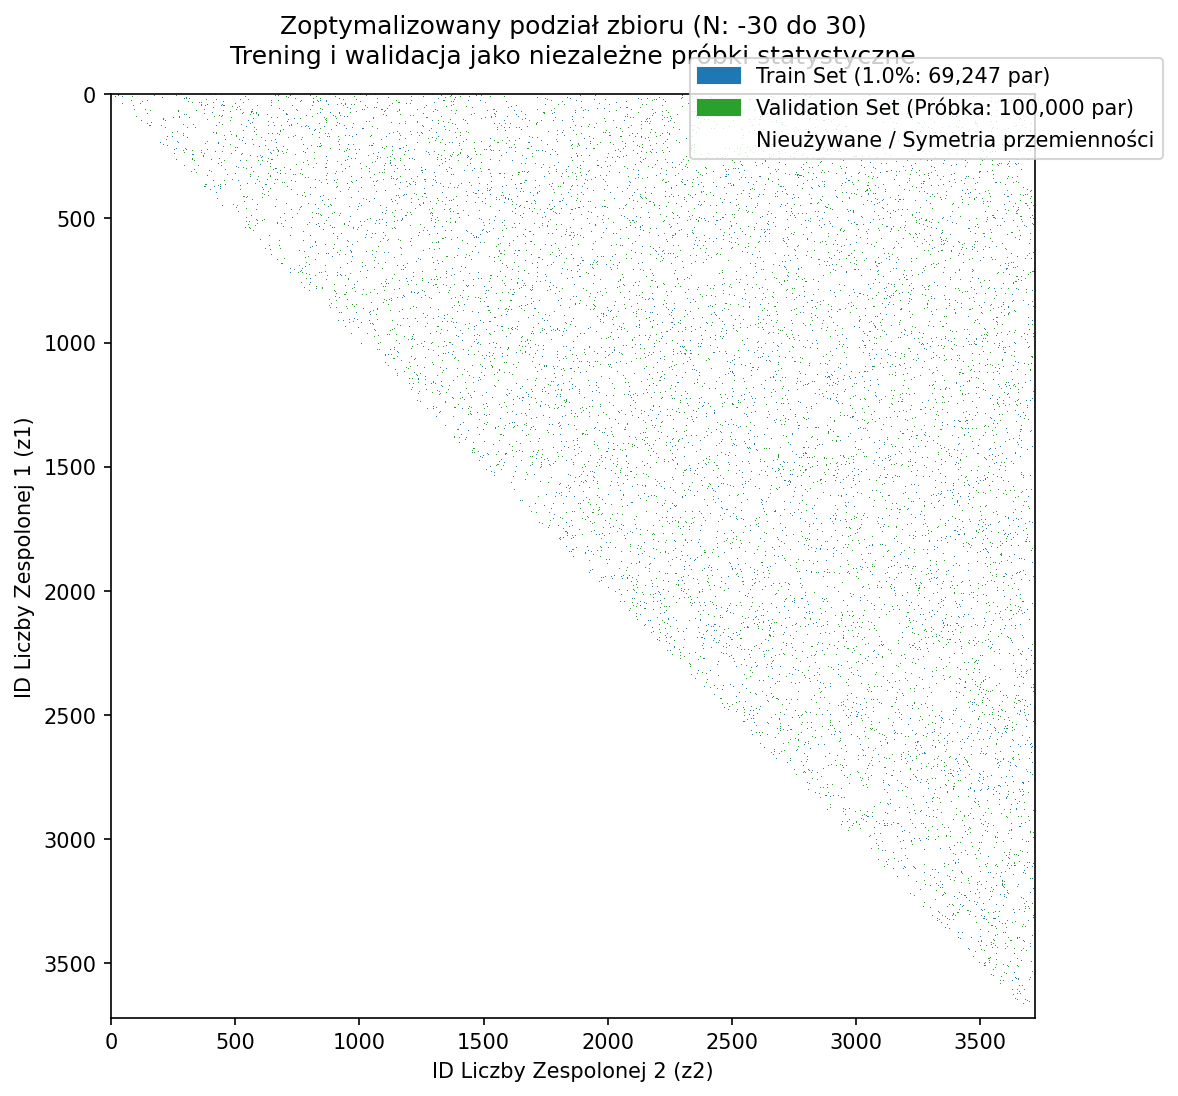

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def visualize_double_sampling(min_val=-30, max_val=30, train_frac=0.01, val_size=100000, seed=42):
    np.random.seed(seed)
    
    # 1. Generujemy przestrzeń
    complex_domain = []
    for r in range(min_val, max_val + 1):
        for i in range(min_val, max_val + 1):
            complex_domain.append((r, i))
    K = len(complex_domain)
    
    grid = np.zeros((K, K), dtype=int)
    
    # 2. Indeksy unikalne (trójkąt)
    triu_indices = np.triu_indices(K)
    unique_pairs_idx = np.column_stack((triu_indices[0], triu_indices[1]))
    total_unique = len(unique_pairs_idx)
    
    # 3. Losujemy indeksy dla Train i dla Val z puli unikalnych par
    num_train = int(total_unique * train_frac)
    
    shuffled_indices = np.random.permutation(total_unique)
    
    train_selection = unique_pairs_idx[shuffled_indices[:num_train]]
    val_selection = unique_pairs_idx[shuffled_indices[num_train : num_train + val_size]]
    
    # Kodowanie kolorów: 0=tło/ignorowane, 1=Validation, 2=Train
    grid[val_selection[:, 0], val_selection[:, 1]] = 1
    grid[train_selection[:, 0], train_selection[:, 1]] = 2
    
    # --- WYKRES ---
    plt.figure(figsize=(10, 8), dpi=150)
    from matplotlib.colors import ListedColormap
    
    # biały (tło), zielony (val), niebieski (train)
    cmap = ListedColormap(['#ffffff', '#2ca02c', '#1f77b4'])
    
    plt.imshow(grid, cmap=cmap, interpolation='nearest')
    
    import matplotlib.patches as mpatches
    train_patch = mpatches.Patch(color='#1f77b4', label=f'Train Set ({train_frac*100}%: {num_train:,} par)')
    val_patch = mpatches.Patch(color='#2ca02c', label=f'Validation Set (Próbka: {val_size:,} par)')
    bg_patch = mpatches.Patch(color='#ffffff', edgecolor='#cccccc', label='Nieużywane / Symetria przemienności')
    
    plt.legend(handles=[train_patch, val_patch, bg_patch], loc='upper right', bbox_to_anchor=(1.15, 1.05))
    plt.title(f"Zoptymalizowany podział zbioru (N: {min_val} do {max_val})\nTrening i walidacja jako niezależne próbki statystyczne", fontsize=12, pad=15)
    plt.xlabel("ID Liczby Zespolonej 2 (z2)")
    plt.ylabel("ID Liczby Zespolonej 1 (z1)")
    plt.show()

# Odpalenie nowej wersji
visualize_double_sampling(min_val=-30, max_val=30, train_frac=0.01, val_size=100000)